# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import SatelliteImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/satellite_image_classification/",
    "csv_file": "./data/satellite_image_classification/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = SatelliteImageClassificationDataset(dataset_config)

## Show images from the dataset

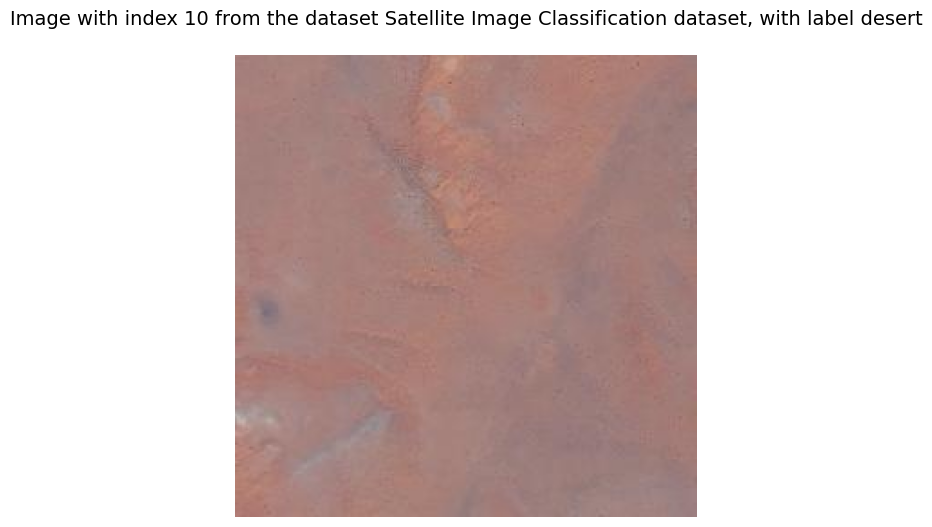

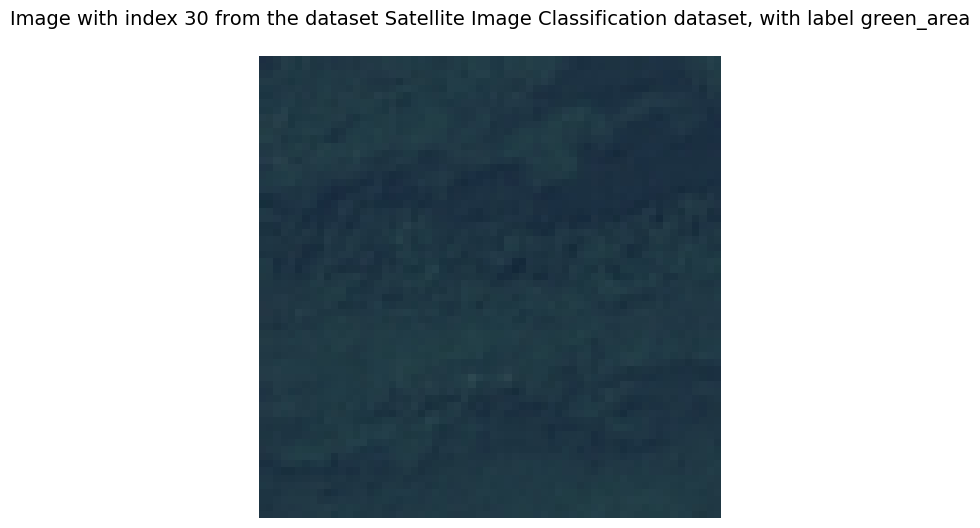

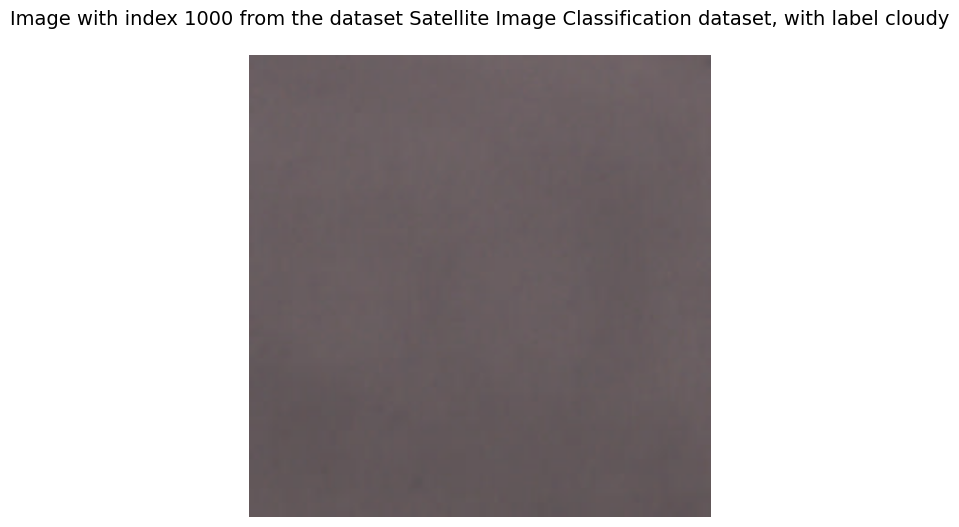

In [28]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(30)
fig3 = dataset.show_image(1000)

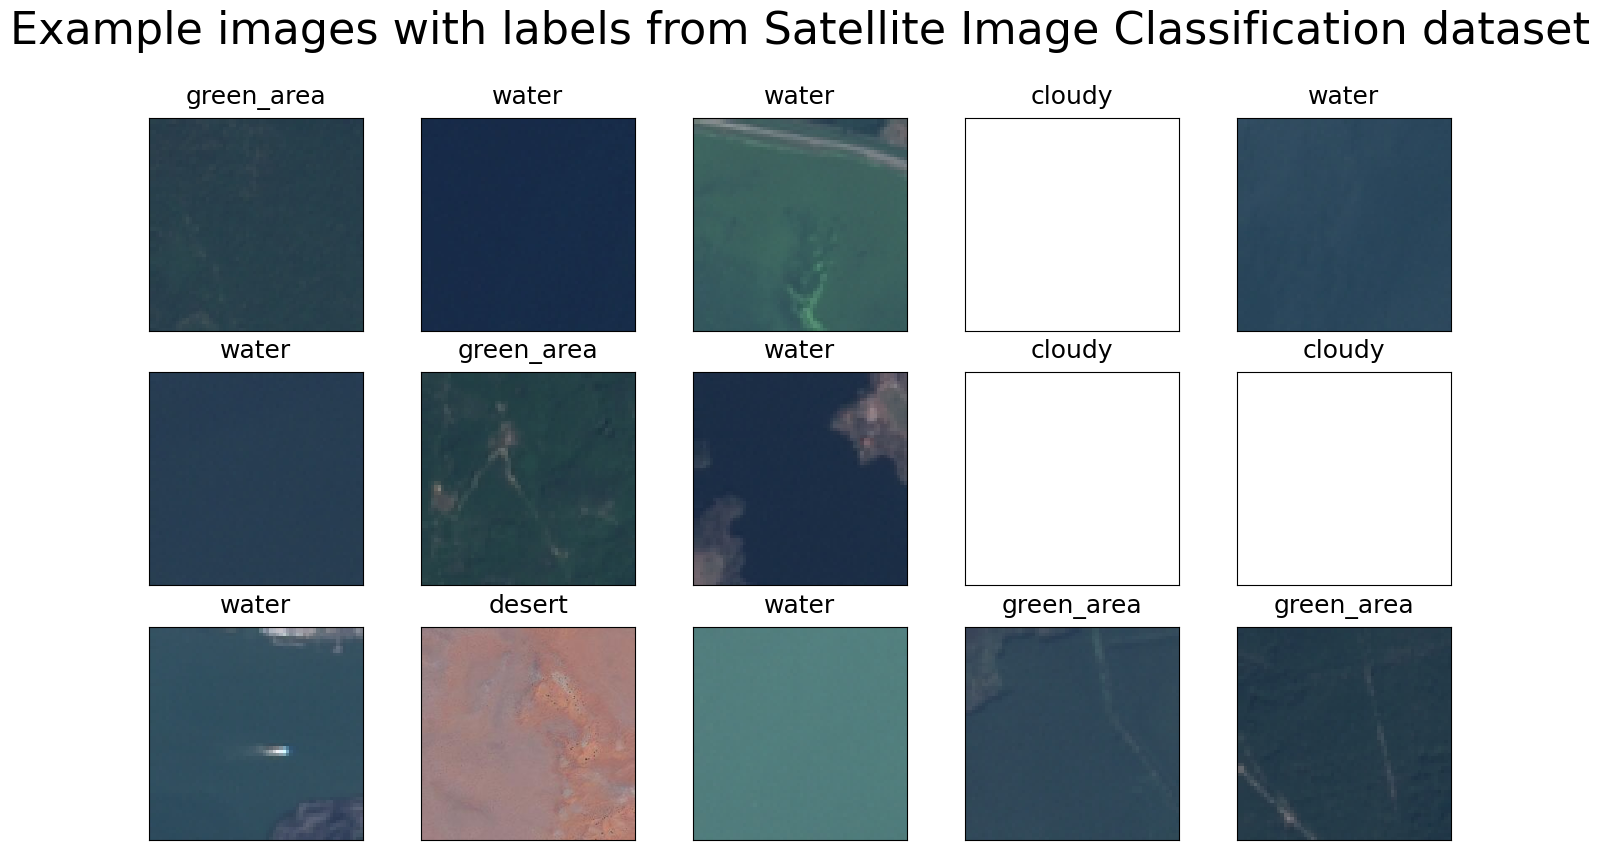

In [10]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [13]:
dataset.show_samples()

,File name,Label
0,cloudy/train_14090.jpg,cloudy
1,cloudy/train_5925.jpg,cloudy
2,water/SeaLake_1507.jpg,water
3,water/SeaLake_203.jpg,water
4,green_area/Forest_2879.jpg,green_area
5,desert/desert(900).jpg,desert
6,desert/desert(357).jpg,desert
7,cloudy/train_33313.jpg,cloudy
8,cloudy/train_9006.jpg,cloudy
9,green_area/Forest_2196.jpg,green_area


In [14]:
dataset.data_distribution_table()

,Label,Count
0,cloudy,1212
1,desert,911
2,green_area,1183
3,water,1199


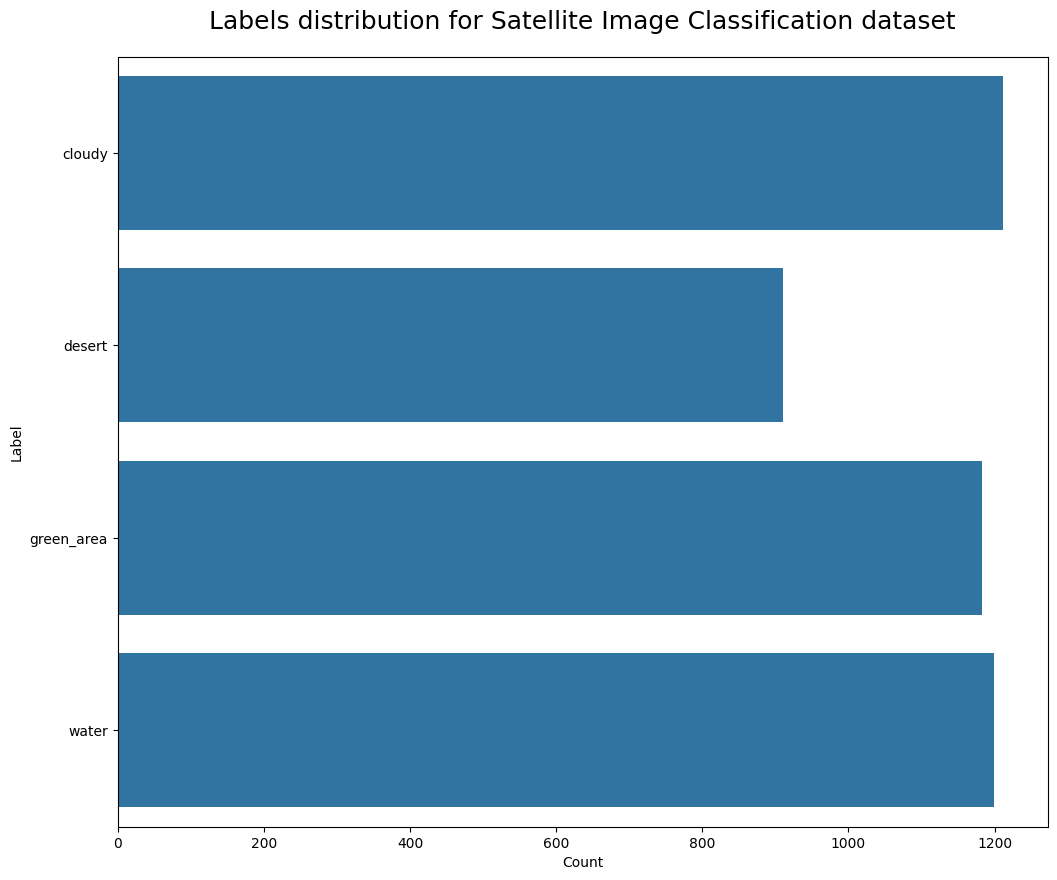

In [15]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/satellite_image_classification/",
    "csv_file": "./data/satellite_image_classification/train.csv",
    "transforms": ["aitlas.transforms.ResizeToTensor"]
}

train_dataset = SatelliteImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/satellite_image_classification/",
    "csv_file": "./data/satellite_image_classification/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = SatelliteImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(4505, 563)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/satellite_image_classification/"
model_config = {
    "num_classes": 4, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-21 06:55:52,101 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-21 06:55:52,301 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-21 06:55:53,940 INFO Starting training.
training: 100%|██████████| 141/141 [01:59<00:00,  1.18it/s]
2025-05-21 06:57:53,642 INFO epoch: 1, time: 119, loss:  0.18648
testing on train set: 100%|██████████| 141/141 [00:43<00:00,  3.21it/s]
2025-05-21 06:58:39,359 INFO Accuracy:0.9960044395116537, Precision Micro:0.9960044395116537, Precision Macro:0.99623220529799, Precision Weighted:0.9960244896926143, Precision per Class:[1.         1.         0.98995816 0.99497066], Recall Micro:0.9960044395116537, Recall Macro:0.9962602911667313, Recall Weighted:0.9960044395116537, Recall per Class:[0.9950495  1.         1.         0.98999166], F1_score Micro:0.9960044395116532, F1_score Macro:0.9962368173626671, F1_score Weighted:0.9960044968090083, F1_score per Class:[0.99751861 1.         0.99495374 0.99247492]
testing on validation set: 100%|██████████| 18/18 [00:05<00:00,  3.12it/s]
2025-05-21 06:58:45,144 INFO Accuracy:0.9982238010657194, Precision Micro:0.9982238010657194, Precision Mac

0.012526207894035671

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/satellite_image_classification/",
    "csv_file": "./data/satellite_image_classification/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = SatelliteImageClassificationDataset(test_dataset_config)
model_path = "./data/experiments/satellite_image_classification/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-21 07:23:36,887 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/satellite_image_classification/checkpoint.pth.tar
2025-05-21 07:23:38,420 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/satellite_image_classification/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 36/36 [00:06<00:00,  5.24it/s]


[{'Accuracy': 0.9893428063943162},
 {'Precision Micro': 0.9893428063943162,
  'Precision Macro': 0.9904403731406001,
  'Precision Weighted': 0.989454313294384,
  'Precision per Class': array([0.98630137, 1.        , 1.        , 0.97546012])},
 {'Recall Micro': 0.9893428063943162,
  'Recall Macro': 0.9901367149598739,
  'Recall Weighted': 0.9893428063943162,
  'Recall per Class': array([0.99310345, 1.        , 0.97986577, 0.98757764])},
 {'F1_score Micro': 0.9893428063943156,
  'F1_score Macro': 0.990250677901385,
  'F1_score Weighted': 0.9893577600717678,
  'F1_score per Class': array([0.98969072, 1.        , 0.98983051, 0.98148148])}]

## Predictions

2025-05-21 07:23:45,315 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/satellite_image_classification/checkpoint.pth.tar
2025-05-21 07:23:46,818 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/satellite_image_classification/checkpoint.pth.tar at epoch 11


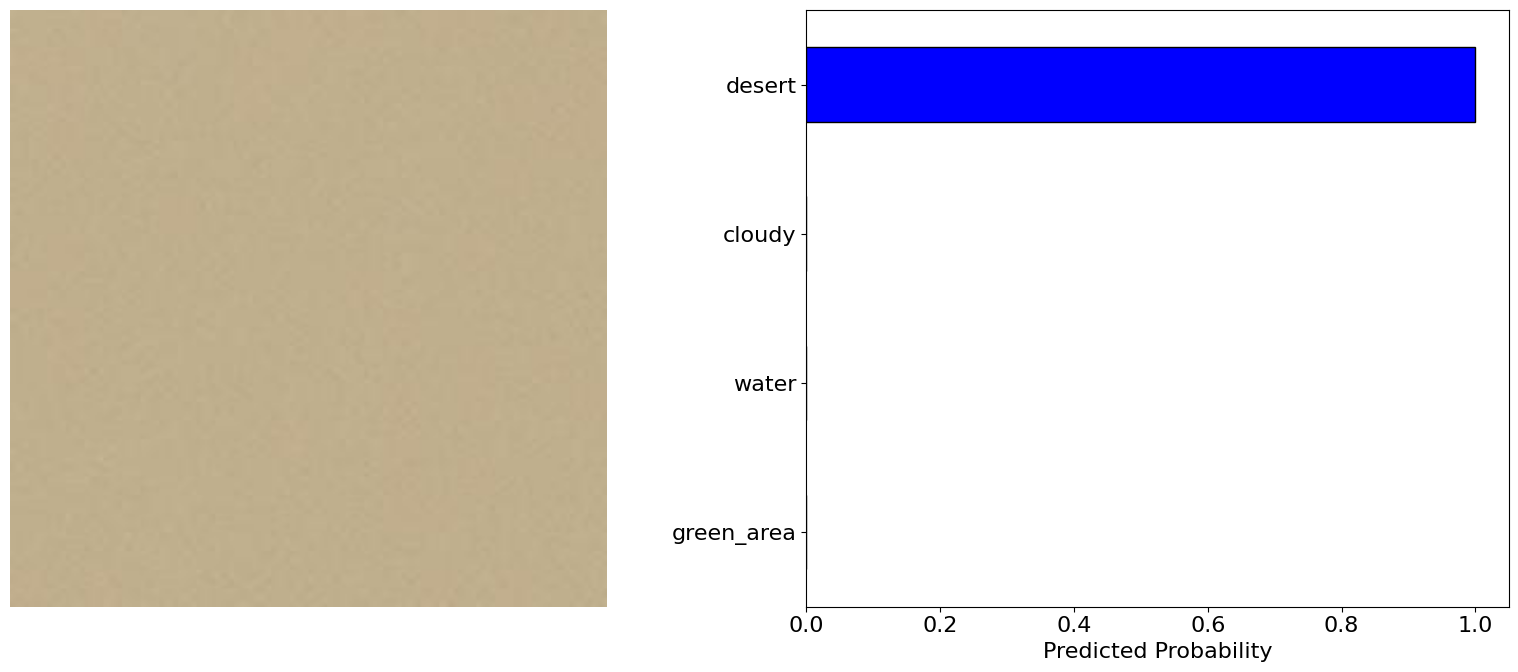

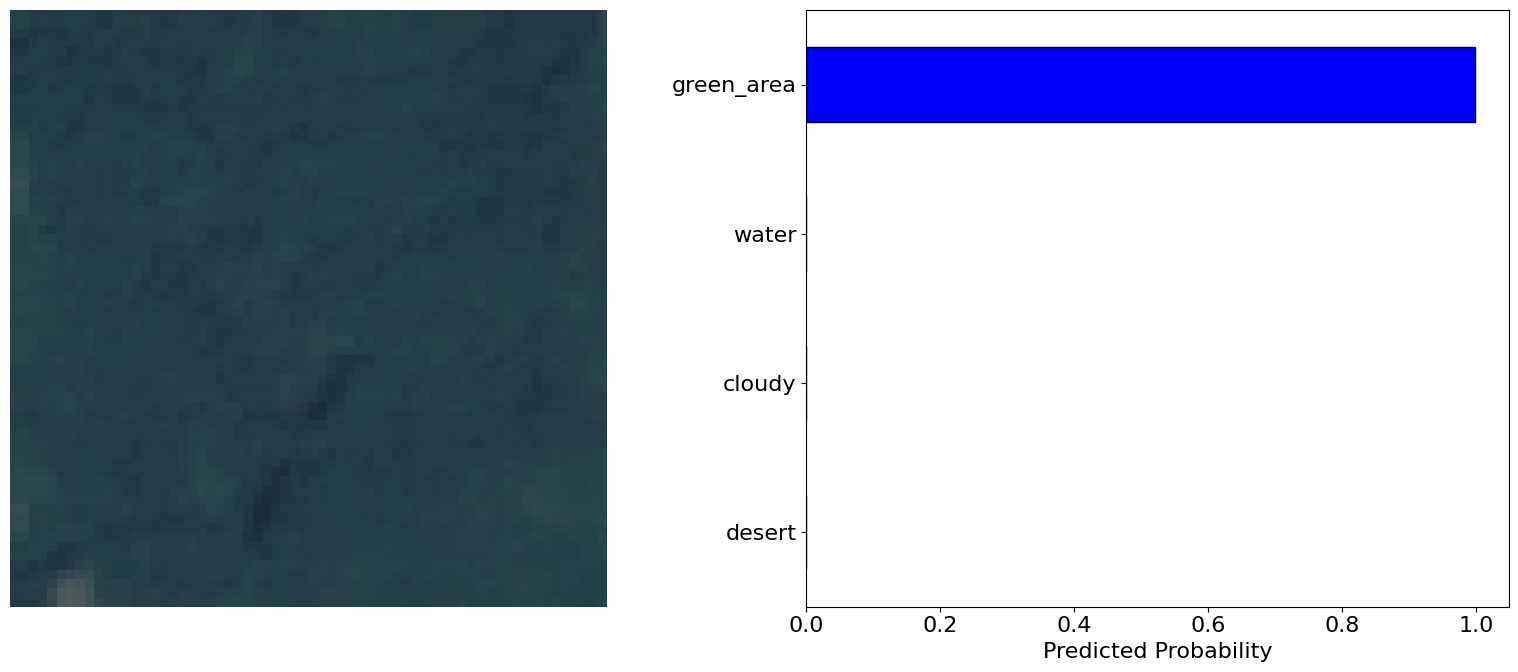

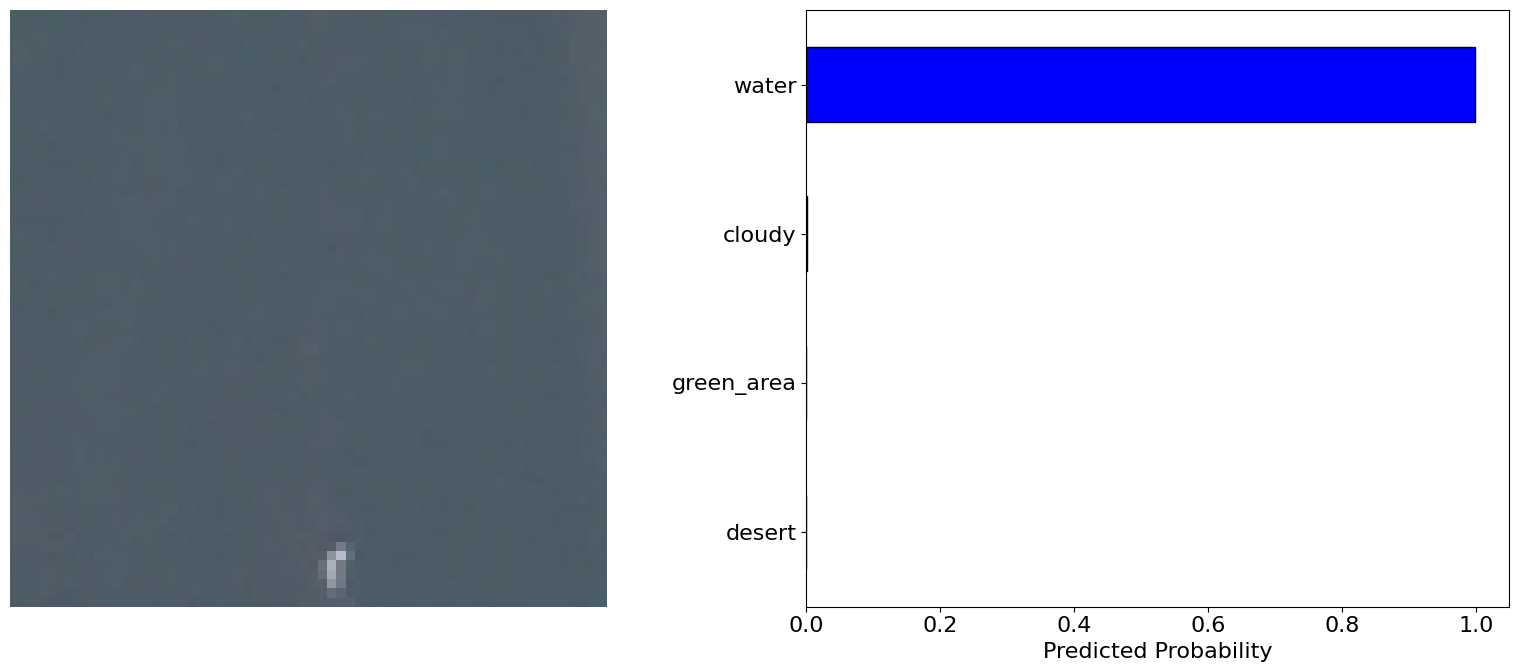

In [ ]:
labels = ["cloudy","desert","green_area","water"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/satellite_image_classification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/satellite_image_classification/desert/desert(963).jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/satellite_image_classification/green_area/Forest_2024.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/satellite_image_classification/water/SeaLake_1954.jpg')
fig = model.predict_image(image, labels, transform)